# Online Retail Customer Future Spending Prediction

## 1. Problem Definition

### Problem Statement

The objective of this project is to develop a Machine Learning model that predicts the future spending of an online retail customer based on their previous purchasing behavior.

The dataset contains transaction-level information such as invoice number, product code, quantity purchased, invoice date, unit price, customer ID, and country.

Since the target variable is a continuous numerical value representing customer spending, this problem is treated as a **Regression problem**.

### Objectives

The main objectives of this project are:

* Understand and analyze the Online Retail dataset.
* Perform Exploratory Data Analysis (EDA).
* Handle missing values and duplicate records.
* Identify and handle invalid transactions and outliers wherever required.
* Create meaningful customer-level features from transaction data.
* Select relevant features for prediction.
* Build and compare multiple suitable regression models.
* Evaluate the models using appropriate regression metrics.
* Perform hyperparameter tuning when required.
* Select the best-performing model.
* Use the selected model to predict spending for unseen customer data.
* Draw a final conclusion based on the model performance.

### Machine Learning Type

**Supervised Learning – Regression**

### Target

**Future Customer Spending**

### Evaluation Metrics

The models will be evaluated using:

* Mean Absolute Error (MAE)
* Root Mean Squared Error (RMSE)
* R² Score


## 2. Import Required Libraries

The required Python libraries are imported for data manipulation, visualization, preprocessing, Machine Learning model development, and model evaluation.

Pandas and NumPy are used for data processing. Matplotlib and Seaborn are used for visualization. Scikit-learn will be used for preprocessing, model building, and evaluation.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Loading the Dataset

The Online Retail dataset is loaded into a Pandas DataFrame.

A DataFrame provides a convenient tabular structure for inspecting, cleaning, transforming, and analyzing the transaction data before applying Machine Learning algorithms.


In [3]:
df = pd.read_csv(
    "../data/OnlineRetail.csv",
    encoding="latin1"
)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [5]:
df.shape

(541909, 8)

In [6]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [7]:
df.dtypes

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 67.3 MB


In [9]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [10]:
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


## 5. Exploratory Data Analysis

Exploratory Data Analysis is performed to understand the distribution and relationships within the dataset.

EDA helps identify patterns, unusual values, potential outliers, and important characteristics of customer purchasing behavior. The findings will also guide the preprocessing and feature engineering stages.


### 5.1 Missing Value Analysis

Missing values can affect data analysis and Machine Learning models. Therefore, the number and percentage of missing values in each column are calculated.

The results will be used to decide the appropriate treatment for missing values rather than applying the same method to every column.


In [11]:
missing_values = df.isnull().sum()

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Percentage": missing_percentage
})

missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

,Missing Values,Percentage
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


### 5.2 Duplicate Record Analysis

Duplicate records may cause the same transaction to be counted multiple times and can affect the analysis and Machine Learning model.

Therefore, duplicate rows are identified before deciding whether they should be removed.


In [12]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 5268


### 5.3 Data Type Analysis

The data types of the columns are checked to ensure that each variable has the correct representation.

For example, `InvoiceDate` should be treated as a date-time variable rather than a string so that useful time-based features can later be extracted.


In [13]:
df.dtypes

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object

In [14]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [15]:
df["InvoiceDate"].dtype

dtype('<M8[us]')

In [16]:
print("Minimum date:", df["InvoiceDate"].min())
print("Maximum date:", df["InvoiceDate"].max())

Minimum date: 2010-12-01 08:26:00
Maximum date: 2011-12-09 12:50:00


### 5.6 Quantity Analysis

The `Quantity` column represents the number of products involved in a transaction.

Its distribution and unusual values are examined because negative or extremely large quantities may represent returns, cancellations, or unusual transactions rather than normal purchases.


In [17]:
df["Quantity"].describe()

count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [18]:
print("Negative quantity records:", (df["Quantity"] < 0).sum())

Negative quantity records: 10624


In [19]:
df["UnitPrice"].describe()

count    541909.000000
mean          4.611114
std          96.759853
min      -11062.060000
25%           1.250000
50%           2.080000
75%           4.130000
max       38970.000000
Name: UnitPrice, dtype: float64

In [20]:
print("Zero or negative prices:", (df["UnitPrice"] <= 0).sum())

Zero or negative prices: 2517


In [21]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

print("Cancelled transactions:", cancelled.sum())

Cancelled transactions: 9288


In [22]:
df[cancelled].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [23]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

In [24]:
df[["Quantity", "UnitPrice", "TotalAmount"]].head()

,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


### 5.9 Transaction Revenue

A new feature called `TotalAmount` is created by multiplying the quantity purchased by the unit price.

This represents the monetary value of each transaction and will be useful for calculating customer spending.


## 6. Data Preprocessing

Data preprocessing is performed to improve the quality and consistency of the dataset before Machine Learning.

The preprocessing decisions are based on the observations obtained during EDA. Invalid transactions, duplicate records, and missing customer identifiers are handled where necessary.


In [25]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (536641, 9)


In [26]:
df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
]

In [27]:
df = df[df["Quantity"] > 0]

In [28]:
df = df[df["UnitPrice"] > 0]

In [29]:
print("Missing CustomerID:", df["CustomerID"].isnull().sum())

Missing CustomerID: 132186


In [30]:
df = df.dropna(subset=["CustomerID"])

## 7. Feature Engineering

The original dataset contains transaction-level records, while our objective is to predict future customer spending.

Therefore, transaction-level data is transformed into customer-level features. These features summarize the customer's previous purchasing behavior, such as total amount spent, number of orders, total quantity purchased, average order value, and number of unique products purchased.

These features will be used as input variables for the Machine Learning models.


In [31]:
print("Minimum date:", df["InvoiceDate"].min())
print("Maximum date:", df["InvoiceDate"].max())

Minimum date: 2010-12-01 08:26:00
Maximum date: 2011-12-09 12:50:00


### 7.3 Time-Based Feature and Target Creation

Since retail transactions occur over time, a time-based approach is used instead of randomly mixing past and future transactions.

The earlier transaction period is used to create customer features, while a later period is used to calculate future customer spending. This ensures that the model learns from information that would actually have been available before the prediction period.

In [32]:
cutoff_date = df["InvoiceDate"].max() - pd.Timedelta(days=30)

print("Cutoff date:", cutoff_date)

Cutoff date: 2011-11-09 12:50:00


In [33]:
past_data = df[df["InvoiceDate"] < cutoff_date].copy()

future_data = df[df["InvoiceDate"] >= cutoff_date].copy()

print("Past records:", len(past_data))
print("Future records:", len(future_data))

Past records: 328431
Future records: 64261


In [34]:
import os

file_path = "../data/OnlineRetail.csv"

print("File exists:", os.path.exists(file_path))
print("File size:", os.path.getsize(file_path), "bytes")

File exists: True
File size: 45580638 bytes


### 7.5 Customer-Level Feature Creation

Customer-level features are created using only transactions from the past period.

The selected features represent different aspects of customer purchasing behavior. These include spending, purchasing frequency, quantity purchased, average transaction value, product variety, and average unit price.

In [35]:
customer_features = past_data.groupby("CustomerID").agg(
    TotalSpent=("TotalAmount", "sum"),
    NumberOfOrders=("InvoiceNo", "nunique"),
    TotalQuantity=("Quantity", "sum"),
    AverageOrderValue=("TotalAmount", "mean"),
    UniqueProducts=("StockCode", "nunique"),
    AverageUnitPrice=("UnitPrice", "mean")
).reset_index()

In [36]:
customer_features.head()

,CustomerID,TotalSpent,NumberOfOrders,TotalQuantity,AverageOrderValue,UniqueProducts,AverageUnitPrice
0,12346.0,77183.60,1,74215,77183.600000,1,1.040000
1,12347.0,4085.18,6,2266,23.889942,100,2.734912
2,12348.0,1797.24,4,2341,57.975484,22,5.764839
3,12350.0,334.40,1,197,19.670588,17,3.841176
4,12352.0,2506.04,8,536,29.482824,59,15.930706


### 7.7 Target Variable Creation

The target variable represents the amount that each customer spends during the future prediction period.

Only future transactions are used to calculate the target. This ensures that the target is separate from the historical features used by the model.

In [37]:
future_spending = future_data.groupby("CustomerID")["TotalAmount"].sum().reset_index()

future_spending = future_spending.rename(
    columns={"TotalAmount": "FutureSpending"}
)

In [38]:
future_spending.head()

,CustomerID,FutureSpending
0,12347.0,224.82
1,12349.0,1757.55
2,12356.0,58.35
3,12358.0,683.20
4,12362.0,529.04


In [39]:
model_data = customer_features.merge(
    future_spending,
    on="CustomerID",
    how="left"
)

In [40]:
model_data.head()

,CustomerID,TotalSpent,NumberOfOrders,TotalQuantity,AverageOrderValue,UniqueProducts,AverageUnitPrice,FutureSpending
0,12346.0,77183.60,1,74215,77183.600000,1,1.040000,NaN
1,12347.0,4085.18,6,2266,23.889942,100,2.734912,224.82
2,12348.0,1797.24,4,2341,57.975484,22,5.764839,NaN
3,12350.0,334.40,1,197,19.670588,17,3.841176,NaN
4,12352.0,2506.04,8,536,29.482824,59,15.930706,NaN


In [41]:
model_data["FutureSpending"] = model_data["FutureSpending"].fillna(0)

In [42]:
model_data.isnull().sum()

CustomerID           0
TotalSpent           0
NumberOfOrders       0
TotalQuantity        0
AverageOrderValue    0
UniqueProducts       0
AverageUnitPrice     0
FutureSpending       0
dtype: int64

In [43]:
model_data.shape

(4070, 8)

In [44]:
model_data.describe()

,CustomerID,TotalSpent,NumberOfOrders,TotalQuantity,AverageOrderValue,UniqueProducts,AverageUnitPrice,FutureSpending
count,4070.000000,4070.000000,4070.000000,4070.000000,4070.000000,4070.000000,4070.000000,4070.000000
mean,15291.999017,1852.860839,3.880590,1078.405160,56.001425,56.894595,4.550818,301.103015
std,1717.093827,8021.117627,6.774135,4539.727913,1232.450824,78.519005,35.261569,2887.144063
min,12346.000000,2.900000,1.000000,1.000000,1.450000,1.000000,0.122500,0.000000
25%,13809.250000,295.607500,1.000000,150.000000,12.668750,15.000000,2.242139,0.000000
50%,15283.500000,637.005000,2.000000,355.000000,17.797500,33.000000,2.964203,0.000000
75%,16762.750000,1537.297500,4.000000,886.000000,25.175758,71.000000,3.910000,229.617500
max,18287.000000,247885.680000,163.000000,173369.000000,77183.600000,1633.000000,2033.100000,168469.600000


## 8. Feature Selection

Feature selection is performed to identify the variables that are useful for predicting future customer spending.

The CustomerID column is an identifier and does not contain meaningful numerical information for prediction, so it is excluded from the input features.

The remaining customer behavior variables are used as predictors.

In [45]:
X = model_data.drop(
    columns=["CustomerID", "FutureSpending"]
)

y = model_data["FutureSpending"]

In [46]:
print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("FutureSpending")

Features:
['TotalSpent', 'NumberOfOrders', 'TotalQuantity', 'AverageOrderValue', 'UniqueProducts', 'AverageUnitPrice']

Target:
FutureSpending


In [47]:
# P-value and R-squared Analysis

import statsmodels.api as sm

X_ols = X.copy()
X_ols = sm.add_constant(X_ols)

ols_model = sm.OLS(y, X_ols).fit()

print("R-squared:", ols_model.rsquared)

print("\nP-values:")
print(ols_model.pvalues)

R-squared: 0.09008700549713422

P-values:
const                3.985270e-01
TotalSpent           3.782668e-07
NumberOfOrders       1.169803e-01
TotalQuantity        1.154934e-01
AverageOrderValue    3.042228e-03
UniqueProducts       4.550191e-03
AverageUnitPrice     8.671701e-01
dtype: float64


### Best Scenario

A good model should have a **high R-squared value** and **p-values less than 0.05** for important features.

In our case:

- **R-squared = 0.0901** → Low, so the overall model fit is weak.
- **P-values < 0.05** → `TotalSpent`, `AverageOrderValue`, and `UniqueProducts` are statistically significant.

**Conclusion:** The model has a **weak overall fit**, but some features are statistically significant. Therefore, this is a **mixed scenario**, not the best scenario.

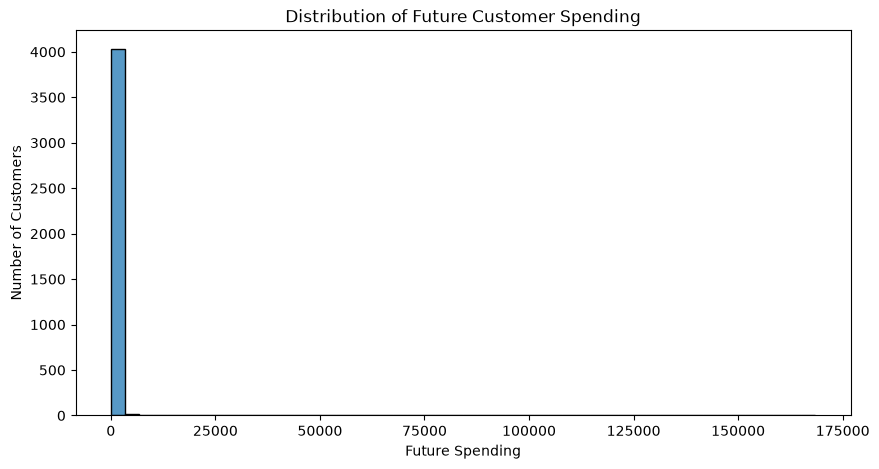

In [48]:
plt.figure(figsize=(10, 5))

sns.histplot(y, bins=50)

plt.title("Distribution of Future Customer Spending")
plt.xlabel("Future Spending")
plt.ylabel("Number of Customers")

plt.show()

In [49]:
y.describe()

count      4070.000000
mean        301.103015
std        2887.144063
min           0.000000
25%           0.000000
50%           0.000000
75%         229.617500
max      168469.600000
Name: FutureSpending, dtype: float64

## 10. Train-Test Split

The customer-level dataset is divided into training and testing sets.

The training data is used to learn the relationship between previous customer behavior and future spending. The testing data is kept separate and is used to evaluate how well the models perform on unseen customers.

An 80:20 split is used, where 80% of the data is used for training and 20% for testing.

In [50]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 3256
Testing samples: 814


## 11. Feature Scaling

Feature scaling is applied because the numerical features have different ranges.

For example, total quantity and average unit price may have very different magnitudes. StandardScaler transforms the features so that they are on a comparable scale.

Scaling is particularly useful for Linear Regression and Ridge Regression.

In [51]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [52]:
scaler.fit_transform(X_train)

array([[-1.48187770e-01, -4.10114117e-01, -2.00527318e-01,
        -3.98343169e-02,  4.55434973e-01, -3.82291340e-02],
       [-1.35873375e-01, -4.10114117e-01, -2.00811777e-01,
        -3.10574947e-02, -2.07846113e-01, -1.22099047e-03],
       [-1.88843757e-01, -1.19603606e-01, -2.42627171e-01,
        -3.25920533e-02, -4.45626124e-01, -9.27753540e-04],
       ...,
       [-1.55424254e-01,  2.56516499e-02, -1.73788222e-01,
        -3.32623513e-02, -2.32875588e-01, -6.27410215e-02],
       [ 5.36858256e-02,  3.16162161e-01, -5.10435207e-03,
        -3.79126145e-02,  1.10620132e+00, -3.07559005e-02],
       [-2.12288033e-01, -4.10114117e-01, -2.46325131e-01,
        -3.67323539e-02, -4.70655599e-01, -4.88079082e-02]],
      shape=(3256, 6))

In [53]:
scaler.transform(X_test)

array([[-0.19397997, -0.41011412, -0.19256248, -0.03322505, -0.43311139,
        -0.08120671],
       [-0.21694361, -0.26485886, -0.21731037, -0.0424013 , -0.03263979,
        -0.08956523],
       [-0.2109215 , -0.26485886, -0.25741901, -0.0205849 , -0.62083245,
        -0.01394817],
       ...,
       [-0.03007623, -0.26485886, -0.10836278, -0.03155514,  0.24268444,
        -0.00183932],
       [ 0.04399357,  0.75192793, -0.01534486, -0.01144322, -0.48317034,
         0.00758843],
       [-0.2090587 , -0.41011412, -0.20052732, -0.03490989, -0.48317034,
        -0.09745087]], shape=(814, 6))

In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 12.1 Linear Regression

Linear Regression is used as the baseline regression model.

It assumes that the target variable can be predicted using a linear relationship between the input features and future customer spending.

The model provides a simple baseline against which more advanced models can be compared.

In [55]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_predictions = linear_model.predict(
    X_test_scaled
)

print("Linear Regression completed")

Linear Regression completed


## 12.2 Ridge Regression

Ridge Regression is a regularized version of Linear Regression.

It adds an L2 penalty to the model coefficients, which helps reduce the effect of very large coefficients and can improve generalization.

Ridge Regression is included to determine whether regularization improves prediction performance.

In [56]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    X_train_scaled,
    y_train
)

ridge_predictions = ridge_model.predict(
    X_test_scaled
)

print("Ridge Regression completed")

Ridge Regression completed


## 12.3 Random Forest Regressor

Random Forest is an ensemble Machine Learning algorithm that combines multiple decision trees.

It can model nonlinear relationships between customer purchasing behavior and future spending. It is therefore suitable for comparing against the linear models.

In [57]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest completed")

Random Forest completed


## 12.4 Gradient Boosting Regressor

Gradient Boosting is an ensemble learning algorithm that builds models sequentially, with each new model attempting to improve the errors made by previous models.

It can capture nonlinear relationships and interactions between customer behavior features and future spending.

In [58]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)

print("Gradient Boosting completed")

Gradient Boosting completed


## 13. Model Evaluation

The trained models are evaluated using three regression metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

MAE measures the average absolute difference between actual and predicted values.

RMSE measures the square root of the average squared prediction error and gives greater importance to larger errors.

R² Score measures how much of the variation in the target variable is explained by the model.

For MAE and RMSE, lower values indicate better performance, while for R², a higher value indicates better performance.

In [59]:
def evaluate_model(model_name, y_actual, y_pred):
    mae = mean_absolute_error(y_actual, y_pred)
    rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
    r2 = r2_score(y_actual, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [60]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_predictions
    )
)

results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        ridge_predictions
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        gb_predictions
    )
)

In [61]:
results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,311.453298,764.529720,0.724528
1,Ridge Regression,311.446193,764.464675,0.724575
2,Random Forest,313.904051,939.295229,0.584193
3,Gradient Boosting,311.645852,929.107815,0.593163


In [62]:
results_df.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,RMSE,R2 Score
1,Ridge Regression,311.446193,764.464675,0.724575
0,Linear Regression,311.453298,764.529720,0.724528
3,Gradient Boosting,311.645852,929.107815,0.593163
2,Random Forest,313.904051,939.295229,0.584193


## 15. Hyperparameter Tuning

Hyperparameter tuning is performed to improve the performance of the selected regression model.

Based on the initial model evaluation, Ridge Regression showed the best performance among the tested models. Therefore, GridSearchCV is applied to Ridge Regression to identify the optimal value of the regularization parameter alpha.

Five different alpha values are tested using 5-fold cross-validation. The model is evaluated using the R² score.

In [63]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

ridge = Ridge()

param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=5,
    scoring="r2"
)

grid_search.fit(
    X_train_scaled,
    y_train
)

print("Best Parameters:", grid_search.best_params_)
print("Best CV R2 Score:", grid_search.best_score_)

Best Parameters: {'alpha': 100}
Best CV R2 Score: 0.30442799290919353


## 16. Evaluation of Tuned Ridge Regression

The best Ridge Regression model obtained from GridSearchCV is evaluated on the unseen test dataset.

The performance is measured using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

In [64]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

best_ridge = grid_search.best_estimator_

tuned_ridge_predictions = best_ridge.predict(
    X_test_scaled
)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_ridge_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tuned_ridge_predictions
    )
)

tuned_r2 = r2_score(
    y_test,
    tuned_ridge_predictions
)

print("Tuned Ridge Regression Results")
print("--------------------------------")
print("MAE :", tuned_mae)
print("RMSE:", tuned_rmse)
print("R2 Score:", tuned_r2)

Tuned Ridge Regression Results
--------------------------------
MAE : 310.9307555627498
RMSE: 760.8155398409651
R2 Score: 0.7271985218522231


## 17. Final Model Comparison

The tuned Ridge Regression model is compared with the previously trained regression models.

The models are compared using MAE, RMSE, and R² Score.

For MAE and RMSE, lower values indicate better performance, while a higher R² Score indicates better predictive performance.

In [65]:
final_results = results_df.copy()

final_results.loc[len(final_results)] = {
    "Model": "Tuned Ridge Regression",
    "MAE": tuned_mae,
    "RMSE": tuned_rmse,
    "R2 Score": tuned_r2
}

final_results = final_results.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

final_results

,Model,MAE,RMSE,R2 Score
0,Tuned Ridge Regression,310.930756,760.815540,0.727199
1,Ridge Regression,311.446193,764.464675,0.724575
2,Linear Regression,311.453298,764.529720,0.724528
3,Gradient Boosting,311.645852,929.107815,0.593163
4,Random Forest,313.904051,939.295229,0.584193


## 18. Best Model Selection

The final model is selected based on the evaluation metrics.

The model with the highest R² Score and comparatively lower MAE and RMSE is considered the best-performing model for predicting customer spending.

In [66]:
best_model = final_results.iloc[0]

print("Best Model:", best_model["Model"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2 Score"])

Best Model: Tuned Ridge Regression
MAE: 310.9307555627498
RMSE: 760.8155398409651
R2 Score: 0.7271985218522231


### Interpretation

Based on the final model comparison, the model with the best overall predictive performance is selected as the final model.

R² Score indicates how well the model explains the variation in customer spending, while MAE and RMSE measure prediction error.

## 19. Actual vs Predicted Analysis

The actual customer spending values are compared with the values predicted by the final tuned Ridge Regression model.

A scatter plot is used to visualize the relationship between actual and predicted values. Predictions closer to the actual values indicate better model performance.

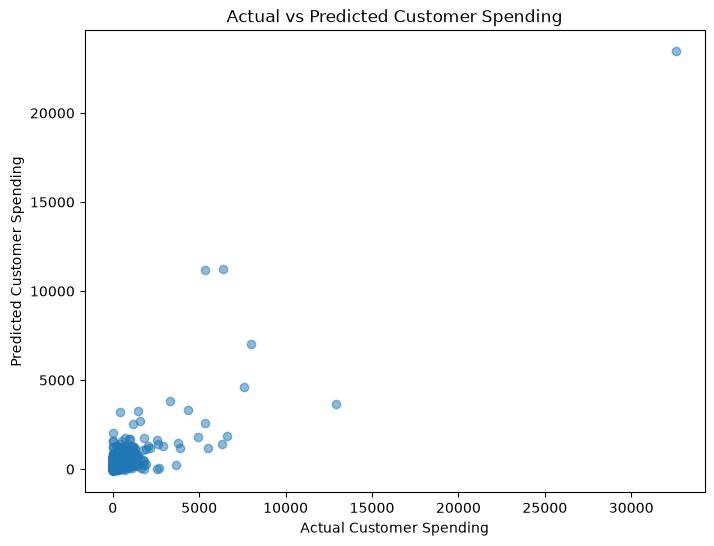

In [67]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    tuned_ridge_predictions,
    alpha=0.5
)

plt.xlabel("Actual Customer Spending")
plt.ylabel("Predicted Customer Spending")
plt.title("Actual vs Predicted Customer Spending")

plt.show()

## 20. Prediction Error Analysis

Prediction errors are calculated as the difference between the actual and predicted customer spending values.

The distribution of errors is visualized using a histogram to understand how the model's prediction errors are distributed.

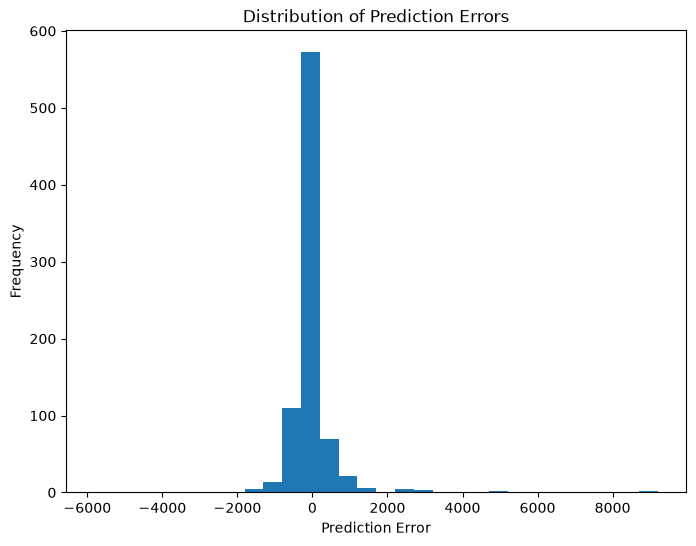

In [68]:
errors = y_test - tuned_ridge_predictions

plt.figure(figsize=(8, 6))

plt.hist(
    errors,
    bins=30
)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Errors")

plt.show()

## 21. Sample Prediction

The trained final model is used to predict the future spending of a sample customer.

An existing customer record from the test dataset is selected as an example. The same preprocessing and scaling applied during model training are applied before generating the prediction.

In [69]:
sample_customer = X_test.iloc[[0]]

sample_customer_scaled = scaler.transform(
    sample_customer
)

sample_prediction = best_ridge.predict(
    sample_customer_scaled
)

print(
    "Predicted Customer Spending:",
    sample_prediction[0]
)

Predicted Customer Spending: 50.19575381344609


## 22. Feature Analysis

The coefficients of the Ridge Regression model are analyzed to understand the relationship between the input features and predicted customer spending.

A positive coefficient indicates a positive relationship with the predicted target, while a negative coefficient indicates a negative relationship.

In [70]:
feature_analysis = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": best_ridge.coef_
})

feature_analysis = feature_analysis.sort_values(
    by="Coefficient",
    ascending=False
)

feature_analysis

,Feature,Coefficient
0,TotalSpent,463.171017
4,UniqueProducts,208.811882
1,NumberOfOrders,116.664455
2,TotalQuantity,90.292232
5,AverageUnitPrice,-7.379075
3,AverageOrderValue,-126.750060


## 23. Feature Coefficient Visualization

The Ridge Regression coefficients are visualized to compare the relative contribution of the input features to the prediction.

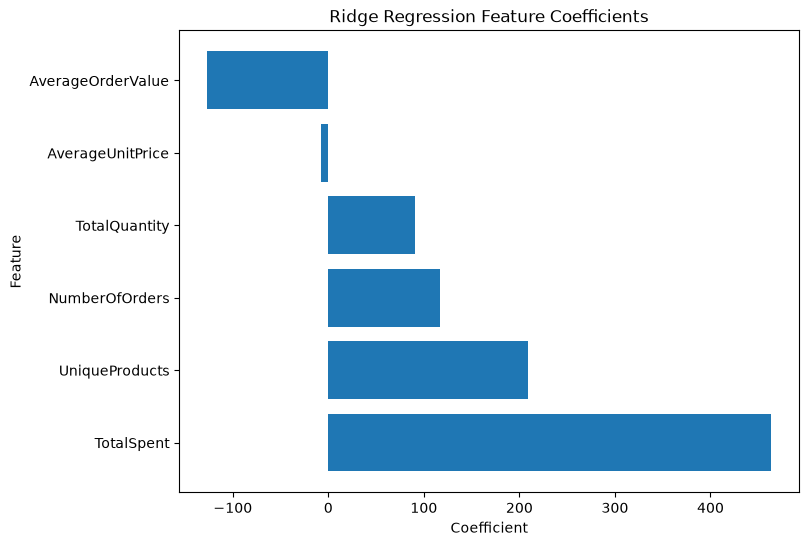

In [71]:
plt.figure(figsize=(8, 6))

plt.barh(
    feature_analysis["Feature"],
    feature_analysis["Coefficient"]
)

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Ridge Regression Feature Coefficients")

plt.show()

## 24. Saving the Final Model

The final trained Ridge Regression model and the StandardScaler are saved so that they can be reused for future predictions without retraining the model.

In [72]:
import joblib

joblib.dump(
    best_ridge,
    "../models/ridge_model.pkl"
)

joblib.dump(
    scaler,
    "../models/scaler.pkl"
)

print("Final model and scaler saved successfully.")

Final model and scaler saved successfully.


## 25. Saving Model Evaluation Results

The final model comparison table is saved as a CSV file for future reference and reporting.

In [73]:
prediction_output = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": tuned_ridge_predictions
})

final_results.to_csv(
    "../outputs/model_comparison.csv",
    index=False
)

prediction_output.to_csv(
    "../outputs/actual_vs_predicted.csv",
    index=False
)

print("Model comparison saved successfully.")
print("Actual vs predicted results saved successfully.")

Model comparison saved successfully.
Actual vs predicted results saved successfully.


# 26. Conclusion

The Online Retail dataset was analyzed to develop a machine learning model for predicting future customer spending.

The project followed a complete machine learning workflow including data understanding, exploratory data analysis, data preprocessing, feature engineering, feature selection, model development, model evaluation, and hyperparameter tuning.

Four regression models were evaluated:

- Linear Regression
- Ridge Regression
- Random Forest Regressor
- Gradient Boosting Regressor

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

Among the initial models, Ridge Regression achieved the best performance. Therefore, hyperparameter tuning was performed using GridSearchCV to identify the optimal regularization parameter.

After hyperparameter tuning, Tuned Ridge Regression achieved the best overall performance with:

- MAE: 310.930756
- RMSE: 760.815540
- R² Score: 0.727199

Therefore, Tuned Ridge Regression was selected as the final model for predicting future customer spending.

Actual-versus-predicted analysis and prediction error analysis were performed to further evaluate the final model. A sample customer prediction was also generated.

The final trained model and scaler were saved in the models directory, while the model comparison and prediction results were saved in the outputs directory.

Overall, this project demonstrates the application of machine learning techniques to Online Retail data for predicting customer spending and supporting data-driven business decisions.

In [74]:
print(X.columns.tolist())

['TotalSpent', 'NumberOfOrders', 'TotalQuantity', 'AverageOrderValue', 'UniqueProducts', 'AverageUnitPrice']


In [75]:
print(y.name)

FutureSpending
